## 1. Load and validate the data

Keep this notebook, the `lecture_methods` folder, and both CSV files in the same directory. If needed, install dependencies in a separate cell with `%pip install -r lecture_methods/requirements.txt`.

In [ ]:
from pathlib import Path
from datetime import datetime
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LAB_DIR = Path.cwd()
if not (LAB_DIR / 'training_data.csv').exists():
    LAB_DIR = LAB_DIR / 'Lab1'
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

train = pd.read_csv(LAB_DIR / 'training_data.csv')
# Accept either duration column name used by the provided CSV files.
if 'duration_ms' in train.columns and 'duration' not in train.columns:
    train = train.rename(columns={'duration_ms': 'duration'})

FEATURES = ['acousticness', 'danceability', 'duration', 'energy',
            'instrumentalness', 'liveness', 'loudness', 'speechiness',
            'tempo', 'valence', 'key', 'mode', 'time_signature']
CATEGORICAL = ['key', 'mode', 'time_signature']
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]
assert set(train.columns) == set(FEATURES + ['label'])
assert not train.label.isna().any() and set(train.label.unique()) == {0, 1}
assert not np.isinf(train[FEATURES].to_numpy(dtype=float)).any()
print('Original shape:', train.shape)


Original shape: (750, 14)


### Exact duplicate records

Some rows have identical features and labels. We treat these as duplicate records and keep one row per group. This reduces the labeled data from 750 to 736 songs. If repeated rows represent meaningful separate observations, this assumption should be reconsidered.

The removal rule does not depend on model scores. If identical features have conflicting labels, stop and inspect them instead of dropping either label.

In [ ]:
duplicates = train.loc[train.duplicated(keep=False)]
clean = train.drop_duplicates().reset_index(drop=True)
# Matching features with different labels need manual inspection.
if clean.duplicated(subset=FEATURES).any():
    raise ValueError('Identical features have conflicting labels; inspect before continuing.')
print('Removed exact duplicates:', len(train) - len(clean))
print('Clean shape:', clean.shape)

OUT = LAB_DIR / 'lecture_runs' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True, exist_ok=False)
duplicates.to_csv(OUT / 'duplicate_records.csv', index_label='original_row')


Removed exact duplicates: 14
Clean shape: (736, 14)


## 2. Holdout split and five-fold cross-validation

Reserve 20% of the labeled data as a stratified holdout set. Use the remaining 80% for model, feature-set, and parameter selection with the same five stratified folds for every candidate. Evaluate the holdout only after selection.

After deduplication, this yields 588 development songs and 148 holdout songs. 

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = clean[FEATURES]
y = clean['label']
# Keep the holdout separate from all feature and parameter comparisons.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))
JOBS = -1
results = {}
print('Development:', len(X_train), 'Holdout:', len(X_holdout))

with (OUT / 'split_indices.json').open('w', encoding='utf-8') as f:
    json.dump({'train': X_train.index.tolist(), 'holdout': X_holdout.index.tolist()}, f, indent=2)


Development: 588 Holdout: 148


## 3. Explore the development data

Inspect only the development data for missing values, feature ranges, class distributions, and category frequencies. These summaries motivate candidate feature sets; they do not determine a model by themselves.

In [ ]:
X_train.info()
display(X_train.isna().sum())
summary = X_train.describe().T
summary['missing'] = X_train.isna().sum()
summary['unique'] = X_train.nunique()
display(summary)
summary.to_csv(OUT / 'data_summary.csv')
labels = y_train.value_counts().sort_index().to_frame('count')
labels['proportion'] = labels['count'] / len(y_train)
display(labels)
labels.to_csv(OUT / 'label_counts.csv')


<class 'pandas.core.frame.DataFrame'>
Index: 588 entries, 317 to 637
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   acousticness      588 non-null    float64
 1   danceability      588 non-null    float64
 2   duration          588 non-null    int64  
 3   energy            588 non-null    float64
 4   instrumentalness  588 non-null    float64
 5   liveness          588 non-null    float64
 6   loudness          588 non-null    float64
 7   speechiness       588 non-null    float64
 8   tempo             588 non-null    float64
 9   valence           588 non-null    float64
 10  key               588 non-null    int64  
 11  mode              588 non-null    int64  
 12  time_signature    588 non-null    int64  
dtypes: float64(9), int64(4)
memory usage: 64.3 KB


,0
acousticness,0
danceability,0
duration,0
energy,0
instrumentalness,0
liveness,0
loudness,0
speechiness,0
tempo,0
valence,0


,count,mean,std,min,25%,50%,75%,max,missing,unique
acousticness,588.0,0.362517,0.339593,0.000001,0.03990,0.24200,0.69975,0.994,0,486
danceability,588.0,0.592745,0.173349,0.107000,0.47000,0.60450,0.71525,0.986,0,404
duration,588.0,221417.653061,69374.150420,33840.000000,185029.75000,215160.00000,246530.00000,675360.000,0,576
energy,588.0,0.594232,0.250384,0.009250,0.43325,0.62100,0.79825,0.995,0,429
instrumentalness,588.0,0.098308,0.257142,0.000000,0.00000,0.00001,0.00236,0.967,0,350
liveness,588.0,0.206297,0.178363,0.024000,0.09465,0.13100,0.27450,0.979,0,385
loudness,588.0,-8.523810,5.133955,-29.601000,-10.06750,-7.34850,-5.02650,-0.533,0,570
speechiness,588.0,0.099606,0.102676,0.023400,0.03565,0.04890,0.11650,0.570,0,403
tempo,588.0,120.167100,27.967387,59.896000,99.01750,119.96300,137.99350,204.162,0,583
valence,588.0,0.497596,0.240549,0.033200,0.29600,0.48300,0.68825,0.975,0,424


,count,proportion
label,,
0,234,0.397959
1,354,0.602041


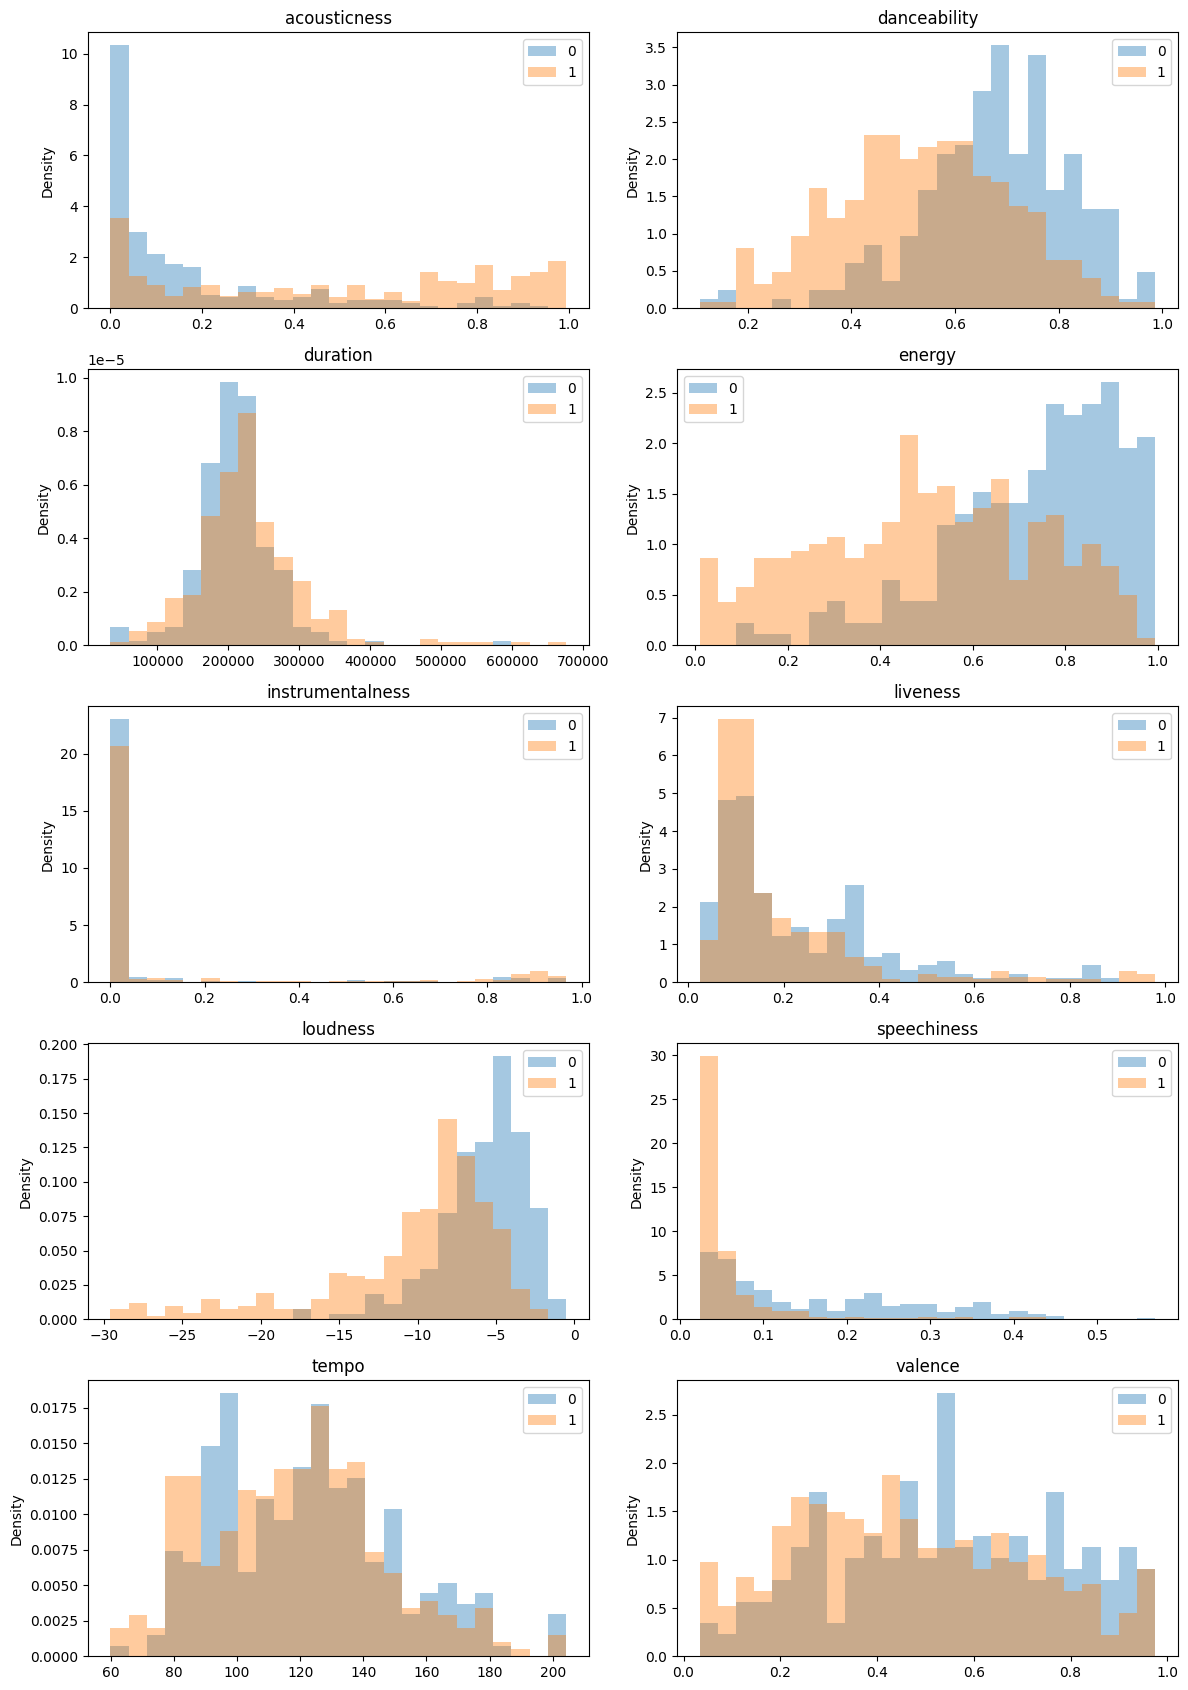

key


,count,like_rate
key,,
0,85,0.788235
1,67,0.358209
2,73,0.698630
3,12,0.666667
4,41,0.731707
5,54,0.592593
6,37,0.513514
7,50,0.580000
8,41,0.414634


mode


,count,like_rate
mode,,
0,150,0.533333
1,438,0.625571


time_signature


,count,like_rate
time_signature,,
1,4,0.750000
3,56,0.821429
4,521,0.581574
5,7,0.285714


In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(12, 17))
for ax, feature in zip(axes.flat, NUMERIC):
    bins = np.histogram_bin_edges(X_train[feature].dropna(), bins=25)
    for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
        values = X_train.loc[y_train == label, feature].dropna()
        ax.hist(values, bins=bins, density=True, alpha=0.4, color=color, label=str(label))
    ax.set_title(feature)
    ax.set_ylabel('Density')
    ax.legend()
plt.tight_layout()
fig.savefig(OUT / 'histograms.png', dpi=130)
plt.show()
plt.close(fig)

for feature in CATEGORICAL:
    table = X_train.assign(label=y_train).groupby(feature).label.agg(count='size', like_rate='mean')
    print(feature)
    display(table)
    table.to_csv(OUT / f'category_{feature}.csv')


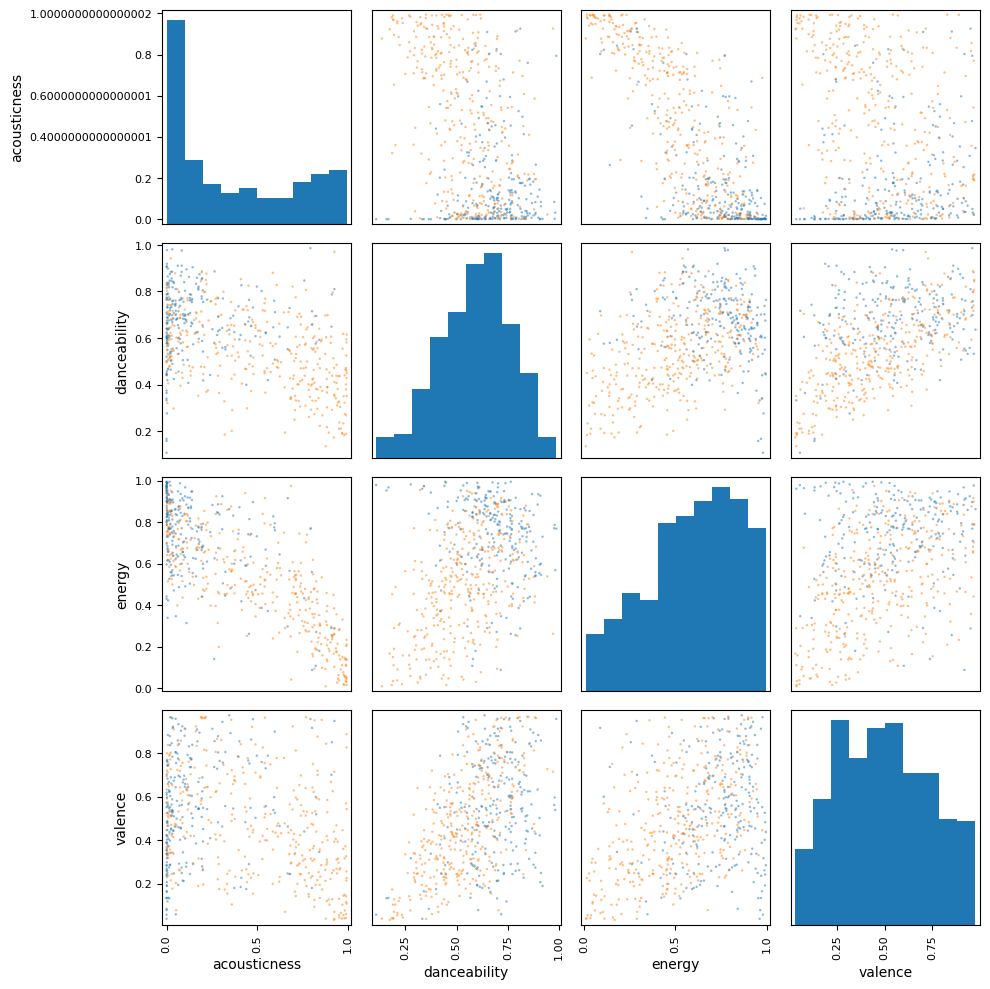

In [ ]:
from pandas.plotting import scatter_matrix

# A readable overview; this plotting choice is not the model's feature selection.
plot_features = ['acousticness', 'danceability', 'energy', 'valence']
axes = scatter_matrix(X_train[plot_features], c=y_train.map({0: 'tab:blue', 1: 'tab:orange'}),
                      diagonal='hist', figsize=(10, 10), alpha=0.5, s=12)
plt.tight_layout()
axes[0, 0].figure.savefig(OUT / 'scatter_matrix.png', dpi=130)
plt.show()
plt.close(axes[0, 0].figure)


## 4. Define candidate feature sets

The class histograms suggest differences for five numerical features, although the classes still overlap. Compare three feature sets to test whether categorical inputs or the remaining features add useful information.

- `A_numeric_5`: acousticness, danceability, energy, loudness, and speechiness.
- `B_plus_categories`: set A plus key, mode, and time signature.
- `C_all`: all 13 original features.

These sets are fixed before cross-validation. Each model compares them with its parameter grid using the same folds. This limited comparison does not establish a globally optimal subset.

In [ ]:
feature_sets = {
    "A_numeric_5": [
        "acousticness", "danceability", "energy",
        "loudness", "speechiness"
    ],
    "B_plus_categories": [
        "acousticness", "danceability", "energy",
        "loudness", "speechiness",
        "key", "mode", "time_signature"
    ],
    "C_all": FEATURES,
}

display(pd.DataFrame([
    {"feature_set": name, "count": len(columns), "features": columns}
    for name, columns in feature_sets.items()
]))


,feature_set,count,features
0,A_numeric_5,5,"[acousticness, danceability, energy, loudness,..."
1,B_plus_categories,8,"[acousticness, danceability, energy, loudness,..."
2,C_all,13,"[acousticness, danceability, duration, energy,..."


## 5. Compare the four classifiers

### Logistic regression

A linear probability model. Compare regularization strengths using `lecture_methods/logistic.py`. Numerical inputs are standardized within each training fold.

In [ ]:
from lecture_methods import logistic

results['Logistic'] = logistic.run(X_train, y_train, feature_sets, cv, jobs=JOBS)
display(results['Logistic']['trials'])
results['Logistic']['trials'].to_csv(OUT / 'logistic_cv.csv', index=False)


Logistic: finished A_numeric_5
Logistic: finished B_plus_categories
Logistic: finished C_all


,feature_set,params,cv_accuracy,cv_std,fold_1,fold_2,fold_3,fold_4,fold_5
0,C_all,{'C': 0.01},0.816210,0.045015,0.881356,0.788136,0.847458,0.811966,0.752137
1,A_numeric_5,{'C': 0.01},0.811097,0.044678,0.881356,0.788136,0.838983,0.794872,0.752137
2,B_plus_categories,{'C': 0.01},0.809387,0.047004,0.881356,0.788136,0.838983,0.794872,0.743590
3,C_all,{'C': 0.1},0.807779,0.025292,0.838983,0.779661,0.830508,0.811966,0.777778
4,B_plus_categories,{'C': 0.1},0.801000,0.040161,0.847458,0.745763,0.822034,0.829060,0.760684
5,A_numeric_5,{'C': 0.1},0.800927,0.045557,0.872881,0.762712,0.822034,0.803419,0.743590
6,B_plus_categories,{'C': 1},0.797639,0.035366,0.822034,0.754237,0.805085,0.846154,0.760684
7,B_plus_categories,{'C': 10},0.797639,0.035303,0.830508,0.745763,0.805085,0.837607,0.769231
8,A_numeric_5,{'C': 1},0.795857,0.036773,0.855932,0.762712,0.805085,0.803419,0.752137
9,C_all,{'C': 10},0.794234,0.022195,0.796610,0.754237,0.822034,0.803419,0.794872


### Random forest

An ensemble of trees trained on resampled data with random feature subsets. Compare tree count, features considered per split, and minimum leaf size using `lecture_methods/random_forest.py`.

In [ ]:
from lecture_methods import random_forest

results['RandomForest'] = random_forest.run(X_train, y_train, feature_sets, cv, jobs=JOBS)
display(results['RandomForest']['trials'])
results['RandomForest']['trials'].to_csv(OUT / 'random_forest_cv.csv', index=False)


RandomForest: finished A_numeric_5
RandomForest: finished B_plus_categories
RandomForest: finished C_all


,feature_set,params,cv_accuracy,cv_std,fold_1,fold_2,fold_3,fold_4,fold_5
0,A_numeric_5,"{'max_features': 'sqrt', 'min_samples_leaf': 5...",0.840099,0.030781,0.855932,0.805085,0.881356,0.854701,0.803419
1,A_numeric_5,"{'max_features': 'sqrt', 'min_samples_leaf': 5...",0.834999,0.033520,0.838983,0.796610,0.889831,0.846154,0.803419
2,C_all,"{'max_features': 0.8, 'min_samples_leaf': 5, '...",0.834985,0.036928,0.855932,0.796610,0.881356,0.854701,0.786325
3,C_all,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",0.831682,0.031315,0.813559,0.796610,0.855932,0.880342,0.811966
4,C_all,"{'max_features': 0.8, 'min_samples_leaf': 5, '...",0.831595,0.035148,0.847458,0.788136,0.881356,0.846154,0.794872
5,A_numeric_5,"{'max_features': 0.8, 'min_samples_leaf': 5, '...",0.831566,0.033215,0.847458,0.805085,0.881356,0.837607,0.786325
6,A_numeric_5,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",0.831551,0.033286,0.822034,0.830508,0.889831,0.829060,0.786325
7,C_all,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",0.829944,0.032689,0.822034,0.796610,0.864407,0.871795,0.794872
8,C_all,"{'max_features': 0.8, 'min_samples_leaf': 1, '...",0.829929,0.031841,0.805085,0.813559,0.872881,0.863248,0.794872
9,B_plus_categories,"{'max_features': 0.8, 'min_samples_leaf': 1, '...",0.829900,0.027083,0.813559,0.822034,0.872881,0.846154,0.794872


### Gradient boosting

An ensemble that adds trees sequentially to correct previous errors. Compare tree count, learning rate, and tree depth using `lecture_methods/gradient_boosting.py`.

In [ ]:
from lecture_methods import gradient_boosting

results['GradientBoosting'] = gradient_boosting.run(X_train, y_train, feature_sets, cv, jobs=JOBS)
display(results['GradientBoosting']['trials'])
results['GradientBoosting']['trials'].to_csv(OUT / 'gradient_boosting_cv.csv', index=False)


GradientBoosting: finished A_numeric_5
GradientBoosting: finished B_plus_categories
GradientBoosting: finished C_all


,feature_set,params,cv_accuracy,cv_std,fold_1,fold_2,fold_3,fold_4,fold_5
0,A_numeric_5,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.838389,0.030578,0.864407,0.796610,0.881356,0.829060,0.820513
1,A_numeric_5,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.834999,0.030793,0.864407,0.788136,0.872881,0.829060,0.820513
2,A_numeric_5,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.834999,0.030793,0.864407,0.788136,0.872881,0.829060,0.820513
3,C_all,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.833362,0.033173,0.847458,0.771186,0.864407,0.854701,0.829060
4,C_all,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.833333,0.039612,0.864407,0.762712,0.872881,0.846154,0.820513
5,C_all,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.833333,0.039612,0.864407,0.762712,0.872881,0.846154,0.820513
6,B_plus_categories,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.833290,0.036003,0.864407,0.779661,0.881356,0.820513,0.820513
7,C_all,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.829987,0.038050,0.855932,0.754237,0.847458,0.846154,0.846154
8,C_all,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.829886,0.039969,0.864407,0.771186,0.881356,0.829060,0.803419
9,B_plus_categories,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.829886,0.043403,0.881356,0.762712,0.872881,0.811966,0.820513


### Linear SVM

A linear classifier that seeks a large-margin boundary. Compare regularization strengths using `lecture_methods/svm_linear.py`. Numerical inputs are standardized within each training fold.

In [ ]:
from lecture_methods import svm_linear

results['SVM_linear'] = svm_linear.run(X_train, y_train, feature_sets, cv, jobs=JOBS)
display(results['SVM_linear']['trials'])
results['SVM_linear']['trials'].to_csv(OUT / 'svm_linear_cv.csv', index=False)


SVM_linear: finished A_numeric_5
SVM_linear: finished B_plus_categories
SVM_linear: finished C_all


,feature_set,params,cv_accuracy,cv_std,fold_1,fold_2,fold_3,fold_4,fold_5
0,C_all,{'C': 0.1},0.814631,0.018056,0.813559,0.788136,0.838983,0.829060,0.803419
1,C_all,{'C': 0.01},0.809489,0.029442,0.838983,0.771186,0.838983,0.820513,0.777778
2,C_all,{'C': 10},0.807866,0.026832,0.796610,0.762712,0.838983,0.829060,0.811966
3,C_all,{'C': 1},0.806157,0.022087,0.796610,0.771186,0.830508,0.829060,0.803419
4,A_numeric_5,{'C': 0.01},0.806026,0.037103,0.864407,0.779661,0.830508,0.794872,0.760684
5,B_plus_categories,{'C': 0.1},0.804433,0.039451,0.830508,0.745763,0.830508,0.846154,0.769231
6,B_plus_categories,{'C': 0.01},0.804346,0.042954,0.864407,0.754237,0.838983,0.803419,0.760684
7,B_plus_categories,{'C': 1},0.797610,0.026072,0.822034,0.762712,0.813559,0.820513,0.769231
8,B_plus_categories,{'C': 10},0.794191,0.034288,0.830508,0.745763,0.822034,0.811966,0.760684
9,A_numeric_5,{'C': 1},0.792438,0.030743,0.838983,0.771186,0.813559,0.786325,0.752137


## 6. Select by cross-validation, then evaluate the holdout

Choose the model, feature set, and parameters by mean five-fold accuracy on the development data. This selected CV score may be optimistic. Record the choice before evaluating the holdout set, and do not retune from the holdout results.

The comparison includes the four model sections above. The majority-class accuracy is shown as a simple baseline.

In [ ]:
comparison = pd.DataFrame([
    {'model': name, 'feature_set': result['feature_set'],
     'cv_accuracy': result['cv_accuracy'], 'cv_std': result['cv_std'],
     'params': result['params'], 'features': result['features']}
    for name, result in results.items()
]).sort_values('cv_accuracy', ascending=False, kind='stable').reset_index(drop=True)
# Stable sorting makes ties follow the order in which models were run.
winner_name = comparison.iloc[0]['model']
winner = results[winner_name]
print('Chosen by CV:', winner_name, winner['feature_set'], winner['params'])
display(comparison)
comparison.to_csv(OUT / 'cv_comparison.csv', index=False)

feature_comparison = pd.DataFrame({
    name: result['trials'].groupby('feature_set')['cv_accuracy'].max()
    for name, result in results.items()
}).T
display(feature_comparison)
feature_comparison.to_csv(OUT / 'feature_comparison.csv')
with (OUT / 'decision_before_holdout.json').open('w', encoding='utf-8') as f:
    json.dump({'model': winner_name, 'feature_set': winner['feature_set'],
               'features': winner['features'], 'params': winner['params']}, f, indent=2)


Chosen by CV: RandomForest A_numeric_5 {'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 300}


,model,feature_set,cv_accuracy,cv_std,params,features
0,RandomForest,A_numeric_5,0.840099,0.030781,"{'max_features': 'sqrt', 'min_samples_leaf': 5...","[acousticness, danceability, energy, loudness,..."
1,Logistic,C_all,0.816210,0.045015,{'C': 0.01},"[acousticness, danceability, duration, energy,..."


feature_set,A_numeric_5,B_plus_categories,C_all
Logistic,0.811097,0.809387,0.816210
RandomForest,0.840099,0.829900,0.834985


,model,holdout_accuracy
0,Logistic,0.817568
1,RandomForest,0.817568
2,SVM_linear,0.763514
3,GradientBoosting,0.817568


Majority baseline: 0.6013513513513513
              precision    recall  f1-score   support

           0       0.83      0.68      0.75        59
           1       0.81      0.91      0.86        89

    accuracy                           0.82       148
   macro avg       0.82      0.79      0.80       148
weighted avg       0.82      0.82      0.81       148



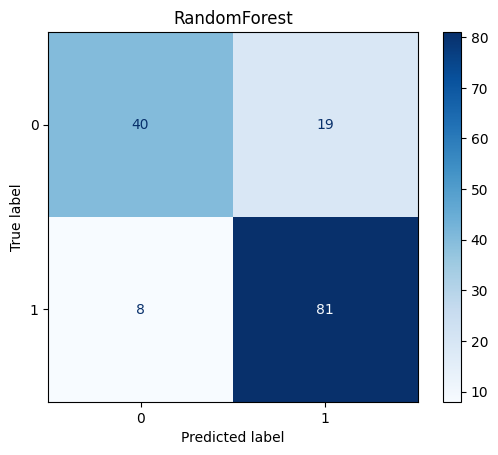

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

holdout_rows = []
for name, result in results.items():
    predicted = result['model'].predict(X_holdout[result['features']])
    holdout_rows.append({'model': name, 'holdout_accuracy': accuracy_score(y_holdout, predicted)})
holdout_scores = pd.DataFrame(holdout_rows)
display(holdout_scores)
holdout_scores.to_csv(OUT / 'holdout_scores.csv', index=False)
print('Majority baseline:', (y_holdout == y_train.mode().iloc[0]).mean())

predicted = winner['model'].predict(X_holdout[winner['features']])
print(classification_report(y_holdout, predicted, labels=[0, 1], zero_division=0))
disp = ConfusionMatrixDisplay.from_predictions(y_holdout, predicted, labels=[0, 1], cmap='Blues')
disp.ax_.set_title(winner_name)
disp.figure_.savefig(OUT / 'chosen_confusion_matrix.png', dpi=130, bbox_inches='tight')
plt.show()
plt.close(disp.figure_)


## 7. Inspect random forest feature importance

The importance values correspond to columns after preprocessing. Several encoded columns can represent one original categorical feature. Correlation and feature cardinality can affect these values; they are not causal effects or a reason to reselect features after holdout evaluation.

In [ ]:
if 'RandomForest' in results:
    forest = results['RandomForest']['model']
    importance = pd.Series(forest.named_steps['model'].feature_importances_,
                           index=forest.named_steps['preprocess'].get_feature_names_out())
    importance = importance.sort_values(ascending=False)
    display(importance)
    importance.to_csv(OUT / 'random_forest_importance.csv', header=['importance'])


,0
numeric__speechiness,0.390381
numeric__acousticness,0.193289
numeric__loudness,0.178287
numeric__energy,0.134396
numeric__danceability,0.103647


## 8. Refit on all labeled data and export predictions (optional)

After model selection, set `RUN_EXPORT = True` to refit the fixed model configuration once on all deduplicated labeled data. Predict the 200 unlabeled songs in their original row order and write the required 0/1 string. No further search is performed.

The unlabeled songs have no local accuracy score. This notebook does not upload predictions to the leaderboard.

In [ ]:
RUN_EXPORT = False
if RUN_EXPORT:
    from sklearn.base import clone
    import joblib

    # Reuse the selected configuration, but fit it on all labeled songs.
    final_model = clone(winner['model'])
    final_model.fit(clean[winner['features']], clean['label'])
    test = pd.read_csv(LAB_DIR / 'songs_to_classify.csv')
    if 'duration_ms' in test.columns and 'duration' not in test.columns:
        test = test.rename(columns={'duration_ms': 'duration'})
    assert len(test) == 200 and set(test.columns) == set(FEATURES)
    prediction = final_model.predict(test[winner['features']]).astype(int)
    submission = ''.join(map(str, prediction))
    assert len(submission) == 200 and set(submission) <= {'0', '1'}
    (OUT / 'submission.txt').write_text(submission, encoding='ascii')
    pd.DataFrame({'row_position': range(200), 'prediction': prediction}).to_csv(OUT / 'test_predictions.csv', index=False)
    joblib.dump(final_model, OUT / 'final_model.joblib')
    print('Saved final model and submission to:', OUT)


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/lecture_methods_export",
    "zip",
    root_dir="/content",
    base_dir="lecture_methods",
)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>